# End-to-end: anomaly detection

This notebook runs one anomaly-detection job from the question to the report: which Berlin Airbnb listings look so unusual that a person should check them first? It uses the same seven steps as every end-to-end notebook of the course, so you can compare the kinds of problems side by side.

*Session 11, end-to-end notebook. Course material, licence CC BY 4.0.*

## 1 The problem

A team at a city office, or at the platform itself, checks rental listings by hand: is the price real, does the flat exist, do the facts fit together? Checking all listings takes too long. The team asks: **which listings should we look at first?**

Some unusual listings are errors (a price typed with two zeros too many), some are rare but real (a large house for 16 guests). Nobody has marked which listings are wrong, so there is no target to learn from. A model can still learn what a usual listing looks like and rank the listings by how much they differ from it. This is **anomaly detection**.

To measure how well a detector works, we need some listings whose answer we know. So in step 4 we plant typing errors of the kind the team looks for into a few listings, and we check whether the detector finds them.

## 2 Load the data

The listings are part of the course data (Inside Airbnb, Berlin, June 2026; see `case-study/data/airbnb/PROVENANCE.md`). The first code cell moves to the repository root, where the data paths start.

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

We import the libraries that every step uses. Each later step imports the scikit-learn parts it needs where it uses them. `sns.set_theme` gives every figure the same clean style.

In [2]:
# matplotlib draws the figures, numpy computes with arrays, pandas holds tables,
# seaborn draws statistical plots on top of matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# One style for every figure: a white background with a light grid, and slightly larger text
sns.set_theme(style="whitegrid", font_scale=1.1)
# Wide tables stay on one line
pd.set_option("display.width", 150)

`pd.read_parquet(..., columns=[...])` reads only the columns we need. We keep the listings that show a price, because the price is the first fact the team checks.

In [3]:
# The columns this notebook uses; reading only these keeps the table small
listing_columns = ["id", "room_type", "price", "accommodates", "bedrooms", "minimum_nights"]
all_listings = pd.read_parquet("case-study/data/airbnb/listings.parquet", columns=listing_columns)
# Keep the rows with a price; reset_index numbers the kept rows 0, 1, 2, ... again
listings = all_listings[all_listings["price"].notna()].reset_index(drop=True)
print(len(all_listings), "listings,", len(listings), "with a price")

10221 listings, 6754 with a price


**What is in the data?** One row is one listing: a flat, a room or a bed that a host offers on Airbnb in Berlin. The table explains the six columns we use. The detectors use four of them (price, minimum stay, guests, bedrooms); `id` and `room_type` only help us read the flagged listings. We leave out the other columns of the file: the number of beds and bathrooms repeat the size of the listing and have even more gaps, and the reviews, the location and the host do not describe whether the listing's own facts fit together.

| column | meaning | unit or values |
|---|---|---|
| `id` | the number Airbnb gives the listing | a whole number; only used to find the listing again |
| `room_type` | what the guest rents | Entire home/apt, Private room, Hotel room or Shared room |
| `price` | the price of one night | euros |
| `accommodates` | the largest number of guests allowed | persons, from 1 to 16 |
| `bedrooms` | the number of bedrooms | a count from 0 to 14; missing for some listings |
| `minimum_nights` | the shortest stay the host accepts | nights, from 1 to 365 |

## 3 Look at the data

`describe()` summarises each number column: how many values it has (`count`), its mean and spread, its smallest and largest value and the quartiles. Compare the median (50%) with the maximum in each column.

In [4]:
# Count, mean, standard deviation, minimum, quartiles and maximum of the four columns the detectors use
listings[["price", "minimum_nights", "accommodates", "bedrooms"]].describe().round(1)

,price,minimum_nights,accommodates,bedrooms
count,6754.0,6753.0,6754.0,5313.0
mean,161.0,20.9,3.4,1.5
std,219.8,38.9,2.2,0.9
min,2.7,1.0,1.0,0.0
25%,70.1,1.0,2.0,1.0
50%,130.0,2.0,2.0,1.0
75%,205.5,7.0,4.0,2.0
max,10025.0,365.0,16.0,14.0


A plot of price against guests shows how the facts fit together. `sns.stripplot` draws one point per listing; `jitter` moves the points a little to the side, so the listings with the same number of guests do not hide each other. The price axis is logarithmic: each step on it multiplies the price by 10, so cheap and expensive listings are both visible.

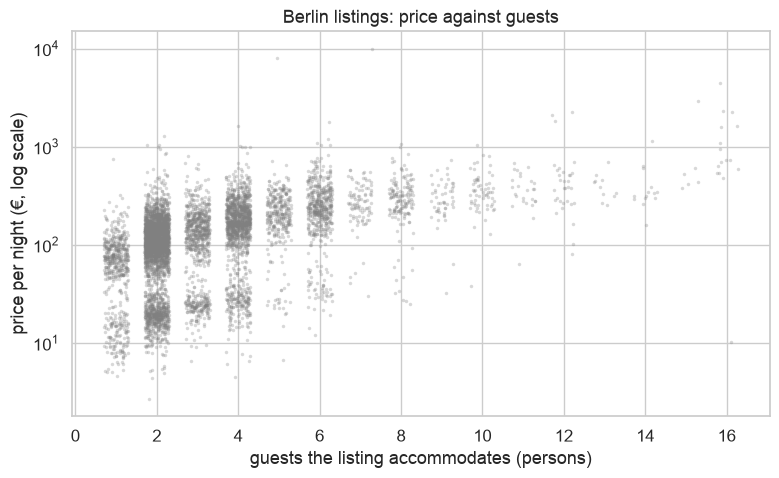

In [5]:
# One point per listing; native_scale=True keeps the guest numbers as positions on a number axis,
# log_scale=(False, True) makes only the price axis logarithmic
fig, ax = plt.subplots(figsize=(9, 5))
sns.stripplot(data=listings, x="accommodates", y="price", native_scale=True, log_scale=(False, True),
              jitter=0.3, size=2.5, alpha=0.3, color="grey", ax=ax)
ax.set_xlabel("guests the listing accommodates (persons)")
ax.set_ylabel("price per night (€, log scale)")
ax.set_title("Berlin listings: price against guests")
plt.show()

**What do you see?** The median price is 130 euros a night, the maximum 10,025; the median minimum stay is 2 nights, the maximum 365. `bedrooms` has 5,313 values for 6,754 listings, so about one in five is missing. In the plot, most listings are for 2 to 4 guests at 50 to 300 euros, and the price rises with the number of guests. Below the main cloud lies a second band of cheap listings at 10 to 30 euros. A few listings for 2 to 7 guests cost more than 1,000 euros. A detector has to decide which of these unusual listings to send to the team, and step 5 has to handle the long tails and the gaps.

## 4 Split the data

There is no target, so there is nothing to predict and no test error in the usual sense. To still measure the detectors, we **plant known errors**: we change 1% of the listings, chosen at random, in one of three ways that the team knows from real typing mistakes:

- **price × 100**: the price is typed with two zeros too many (130 € becomes 13,000 €);
- **price ÷ 100**: the decimal point is in the wrong place (130 € becomes 1.30 €);
- **guests × 10**: the number of guests gets an extra zero (2 becomes 20).

A good detector should rank these planted errors high. The real listings may contain real errors too, but we do not know which, so in the scores below every flagged real listing counts as a **false alarm**. `rng.choice(n, size=k, replace=False)` draws k different row numbers out of n.

In [6]:
# A random generator only for the planting, so the same rows are changed every time
planting_rng = np.random.default_rng(0)
# 1% of the listings, drawn at random without repeats
n_errors = round(0.01 * len(listings))
error_rows = planting_rng.choice(len(listings), size=n_errors, replace=False)

# The three kinds of error, in turn: planted row 0 gets the first kind, row 1 the second, and so on
error_kinds = ["price × 100", "price ÷ 100", "guests × 10"]
listings["planted_error"] = "none"
for position, row in enumerate(error_rows):
    kind = error_kinds[position % 3]
    listings.loc[row, "planted_error"] = kind
    if kind == "price × 100":
        listings.loc[row, "price"] = listings.loc[row, "price"] * 100
    elif kind == "price ÷ 100":
        listings.loc[row, "price"] = round(listings.loc[row, "price"] / 100, 2)
    else:
        listings.loc[row, "accommodates"] = listings.loc[row, "accommodates"] * 10

# is_error is True for a planted error: the answer we check the detectors against
listings["is_error"] = listings["planted_error"] != "none"
# How many listings got each kind of error
listings["planted_error"].value_counts()

planted_error
none           6686
price ÷ 100      23
price × 100      23
guests × 10      22
Name: count, dtype: int64

We have two jobs: choosing the settings of each detector, and reporting how well it works. If we did both on the same listings, the report would look better than it is, as with a test set used for tuning. So we split the listings in two halves: the **tuning listings** to choose the settings, and the **evaluation listings** for the report. `train_test_split(..., test_size=0.5)` makes the two halves; `stratify` keeps the same share of planted errors in both. Each detector is fitted on the half it ranks: the job is to rank the listings we have, not to predict new ones.

In [7]:
from sklearn.model_selection import train_test_split

# Two halves of the listings; stratify keeps 1% planted errors in each; random_state=0 gives the same halves every time
tuning_listings, evaluation_listings = train_test_split(listings, test_size=0.5, stratify=listings["is_error"],
                                                        random_state=0)
print(len(tuning_listings), "tuning listings with", tuning_listings["is_error"].sum(), "planted errors")
print(len(evaluation_listings), "evaluation listings with", evaluation_listings["is_error"].sum(), "planted errors")

3377 tuning listings with 34 planted errors
3377 evaluation listings with 34 planted errors


## 5 Process the data

The detectors use four number columns. Two steps prepare them:

- **Gaps**: `bedrooms` is missing for some listings (and `minimum_nights` for one). `SimpleImputer(strategy="median")` fills each gap with the median of its column.
- **Long tails**: a few prices and stays are many times larger than the median. `FunctionTransformer(np.log1p)` takes the logarithm of 1 + x of every column. Then a price 100 times too high lies a fixed distance away from the right price, whether the right price was 50 € or 500 €, and one column with large numbers cannot outweigh the others.

A `Pipeline` runs the two steps in order. The plot below shows `price` and `minimum_nights` of the tuning listings before and after these steps.

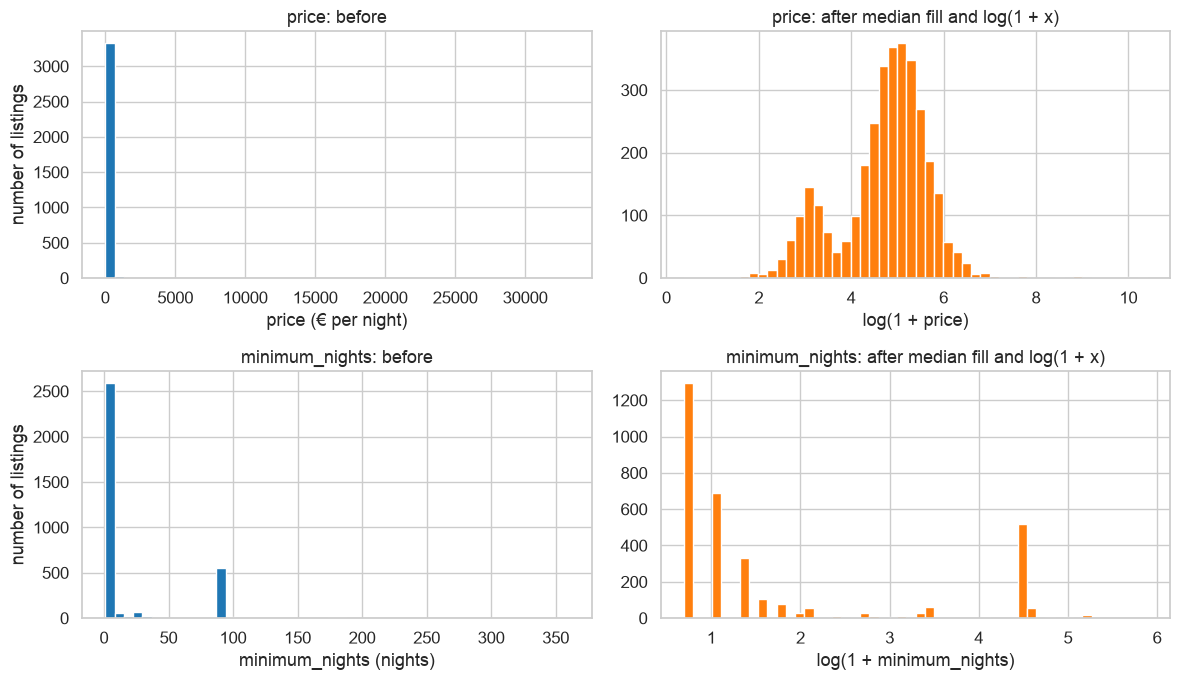

In [8]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

# The four columns the detectors use
feature_columns = ["price", "minimum_nights", "accommodates", "bedrooms"]
# First fill the gaps with the median of each column, then take log(1 + x)
preprocessing = Pipeline([
    ("fill_gaps", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p)),
])
# fit_transform learns the medians from the tuning listings and returns the processed array;
# pd.DataFrame puts it back into a table with the column names, so we can select columns by name
processed_tuning_listings = pd.DataFrame(preprocessing.fit_transform(tuning_listings[feature_columns]),
                                         columns=feature_columns)

# Two rows of panels (price, minimum stay), two columns (before, after)
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for row_axes, column, unit in zip(axes, ["price", "minimum_nights"], ["€ per night", "nights"]):
    ax_before, ax_after = row_axes
    ax_before.hist(tuning_listings[column], bins=50, color="tab:blue")
    ax_before.set_title(f"{column}: before")
    ax_before.set_xlabel(f"{column} ({unit})")
    ax_before.set_ylabel("number of listings")
    ax_after.hist(processed_tuning_listings[column], bins=50, color="tab:orange")
    ax_after.set_title(f"{column}: after median fill and log(1 + x)")
    ax_after.set_xlabel(f"log(1 + {column})")
fig.tight_layout()
plt.show()

**What do you see?** Before processing, almost all prices fall into the first bar: the planted prices × 100 stretch the axis to 33,100 euros, so the usual prices cannot be told apart. After `log(1 + x)`, the prices form a hill around 5 (about 150 euros), with a smaller hill around 3 (about 20 euros), the cheap band of step 3. The planted errors are now visible as thin tails on both sides: 12 tuning listings lie above 8 (prices above about 3,000 euros) and 10 below 1.5 (prices below about 3.50 euros). The minimum stay has two peaks, short stays of up to a week and stays of about 90 nights, and the log spreads the short stays apart.

The local outlier factor in 6.3 compares distances between listings, so it also needs `StandardScaler`, which gives every column a mean of 0 and a standard deviation of 1. Isolation Forest needs no scaling: each split uses one column at a time.

## 6 Run the pipeline

We start with the most common detector, score it, and then improve it one step at a time: Isolation Forest, the same detector tuned on the tuning listings, and then the local outlier factor (LOF), tuned in the same way. The five decisions of the two detectors:

| Decision | Isolation Forest | Local outlier factor |
|---|---|---|
| Data | the four processed listing facts X; no target y | the same, scaled |
| Model | a forest of random trees; a listing that is separated from the others after few random splits is unusual | the density around a listing, compared with the density around its `n_neighbors` nearest listings |
| Loss function | none: the trees split at random columns and random values | none: the score is computed from distances |
| Optimizer | none: building the random trees is the whole training | none: finding the nearest neighbours is the whole training |
| Evaluation | precision, recall and F1 of the flags against the planted errors; a confusion matrix; a loop over a small grid chooses `max_samples` and `contamination` | the same; the loop chooses `n_neighbors` and `contamination` |

Every detector is scored in the same way, on the evaluation listings. A **flagged** listing is one the detector sends to the team. The planted errors are the positive class:

- **Precision** (`precision_score`): of the flagged listings, the share that are planted errors. Low precision means the team spends time on false alarms.
- **Recall** (`recall_score`): of the planted errors, the share the detector flags. Low recall means missed errors.
- **F1** (`f1_score`): one number that is high only when precision and recall are both high (their harmonic mean).

The next cell imports these measures and prepares what every detector cell needs: the evaluation listings and their planted errors, and an empty dictionary that keeps the flags of each detector for step 7.

In [9]:
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score

# The evaluation listings: the four facts, and the answer (True for a planted error) as a NumPy array
evaluation_features = evaluation_listings[feature_columns]
is_planted_error = evaluation_listings["is_error"].to_numpy()
# The flags of every detector, filled by the detector cells of section 6 and used in step 7
flags_by_model = {}

### 6.1 Isolation Forest

`IsolationForest` is the most common detector for tables. It grows random trees: each split picks a random column and a random value. A listing that ends up alone after few splits is unusual. `n_estimators=200` grows 200 trees, so the score does not depend on a few of them; `contamination=0.01` flags the 1% of listings with the highest scores, about as many as the team can check; `random_state=0` fixes the random trees.

The cell fits the detector on the evaluation listings and scores it in four parts:

- `fit_predict` fits the detector and returns −1 for a flagged listing and 1 otherwise.
- Each listing gets an **anomaly score**, higher meaning more unusual: `score_samples` returns it with the opposite sign, so we turn the sign. The detector flags the listings above a **threshold**, which it keeps as `offset_` (with the sign turned in the same way).
- The three measures compare the flags with the planted errors.
- Two figures: the distribution of the anomaly scores with the threshold, and the **confusion matrix**. `confusion_matrix` counts every combination of true and flagged class; `sns.heatmap` draws this 2 × 2 table with the counts written in the cells.

Isolation Forest: 34 flagged, precision 0.118, recall 0.118, F1 0.118


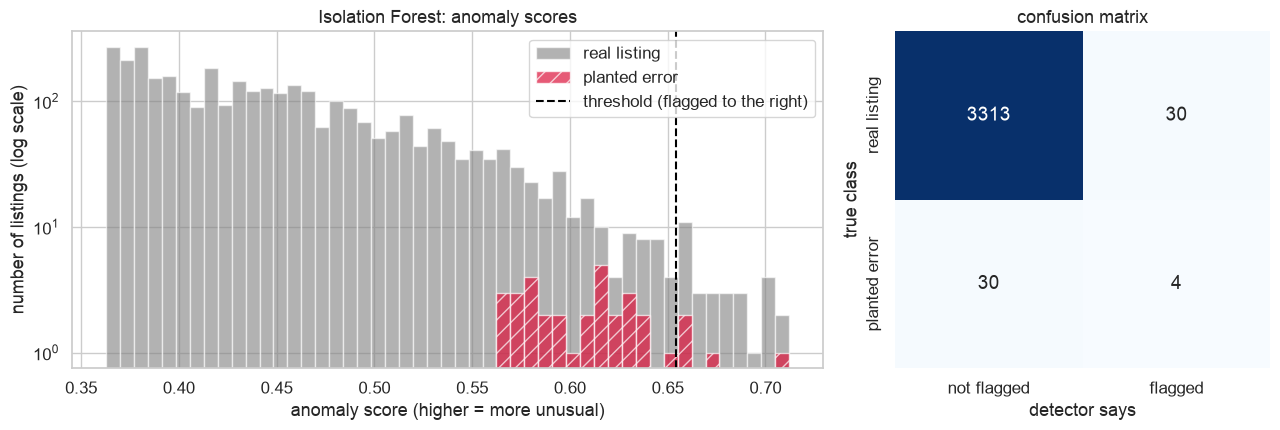

In [10]:
from sklearn.ensemble import IsolationForest

# A Pipeline runs its steps in order: first the processing of step 5, then the detector
forest_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("forest", IsolationForest(n_estimators=200, contamination=0.01, random_state=0)),
])

# fit_predict fits the detector on the evaluation listings and returns -1 for a flagged listing, 1 otherwise
is_flagged = forest_pipeline.fit_predict(evaluation_features) == -1
# Keep the flags for step 7
flags_by_model["Isolation Forest"] = is_flagged
# The anomaly score of every listing, higher = more unusual (score_samples gives it with the opposite sign)
anomaly_score = -forest_pipeline.score_samples(evaluation_features)
# The threshold: forest_pipeline[-1] is the detector step; offset_ is its cut, with the sign turned like the scores
threshold = -forest_pipeline[-1].offset_

# Each metric compares the planted errors with the flags
forest_scores = {
    "model": "Isolation Forest",
    "flagged": int(is_flagged.sum()),
    "precision": precision_score(is_planted_error, is_flagged),
    "recall": recall_score(is_planted_error, is_flagged),
    "F1": f1_score(is_planted_error, is_flagged),
}
print(f"Isolation Forest: {forest_scores['flagged']} flagged, precision {forest_scores['precision']:.3f}, "
      f"recall {forest_scores['recall']:.3f}, F1 {forest_scores['F1']:.3f}")

fig, (ax_scores, ax_counts) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2, 1]})
# Left: one histogram per class on the same bins
# 50 bins of equal width from the lowest to the highest score
bins = np.linspace(anomaly_score.min(), anomaly_score.max(), 50)
ax_scores.hist(anomaly_score[~is_planted_error], bins=bins, color="grey", alpha=0.6, label="real listing")
ax_scores.hist(anomaly_score[is_planted_error], bins=bins, color="crimson", alpha=0.7, hatch="//", label="planted error")
ax_scores.axvline(threshold, color="black", linestyle="--", label="threshold (flagged to the right)")
# The count axis is logarithmic, because there are about 100 real listings for every planted error
ax_scores.set_yscale("log")
ax_scores.set_xlabel("anomaly score (higher = more unusual)")
ax_scores.set_ylabel("number of listings (log scale)")
ax_scores.set_title("Isolation Forest: anomaly scores")
ax_scores.legend()
# Right: confusion_matrix returns a 2 x 2 array of counts, rows = true class, columns = flagged or not;
# sns.heatmap draws it, annot=True writes the counts in the cells, fmt="d" as whole numbers
counts = confusion_matrix(is_planted_error, is_flagged)
sns.heatmap(counts, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 14},
            xticklabels=["not flagged", "flagged"], yticklabels=["real listing", "planted error"], ax=ax_counts)
ax_counts.set_xlabel("detector says")
ax_counts.set_ylabel("true class")
ax_counts.set_title("confusion matrix")
fig.tight_layout()
plt.show()

**What do you see?** With its default settings, Isolation Forest flags 34 listings, but only 4 of them are planted errors: precision and recall are both 0.118. In the histogram, most planted errors have scores of 0.56 to 0.71, but the threshold lies at about 0.65, and many real listings score higher. The 30 false alarms are all entire homes, mostly large ones: 19 are for 10 guests or more, and 18 have 5 bedrooms or more. These homes are rare but real, and to this forest they look more unusual than a price with two zeros too many.

### 6.2 Tune Isolation Forest on the tuning listings

Two settings are **hyperparameters**: we choose them, the detector does not learn them.

- `max_samples`: each tree is grown on a random sample of this many listings. The default is 256; `len(tuning_listings)`, 3,377, means all listings of a half.
- `contamination`: the share of listings to flag, which sets the threshold.

`GridSearchCV` needs a target to cross-validate on and does not fit a detector, so we write the search as a short loop. `ParameterGrid(grid)` lists every combination of the values in `grid`, and `clone(pipeline).set_params(**settings)` makes a fresh, unfitted copy of the pipeline with those settings (`forest__max_samples` means the argument `max_samples` of the step named `forest`). Each copy is fitted on the tuning listings and scored by F1 against their planted errors. The evaluation listings stay unseen until we score the winner.

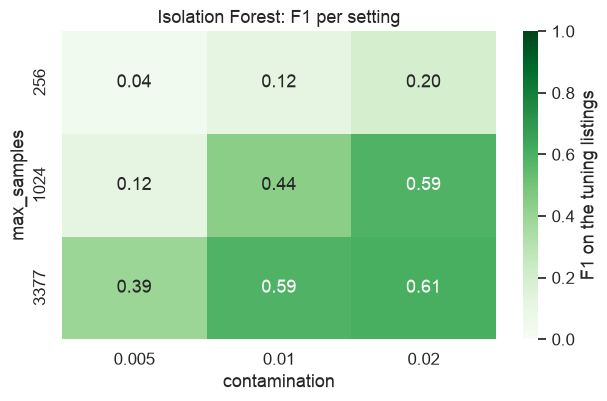

chosen: {'forest__contamination': 0.02, 'forest__max_samples': 3377}


In [11]:
from sklearn.base import clone
from sklearn.model_selection import ParameterGrid

# The tuning listings: the four facts and the planted errors
tuning_features = tuning_listings[feature_columns]
tuning_is_error = tuning_listings["is_error"]

# 3 sample sizes x 3 shares to flag = 9 settings
forest_grid = {"forest__max_samples": [256, 1024, len(tuning_listings)], "forest__contamination": [0.005, 0.01, 0.02]}
# ParameterGrid lists every combination of the values in the grid, as dictionaries
all_settings = list(ParameterGrid(forest_grid))
tuning_f1 = []
for settings in all_settings:
    # A fresh, unfitted copy of the pipeline with this setting
    candidate = clone(forest_pipeline).set_params(**settings)
    # Fit on the tuning listings, flag, and compare the flags with the planted errors
    is_flagged = candidate.fit_predict(tuning_features) == -1
    tuning_f1.append(f1_score(tuning_is_error, is_flagged))

# One row per setting with its F1; pivot makes a table with one cell per combination of the two settings
tuning_results = pd.DataFrame(all_settings)
tuning_results["F1"] = tuning_f1
f1_table = tuning_results.pivot(index="forest__max_samples", columns="forest__contamination", values="F1")
# A heatmap of that table, the F1 written in each cell
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(f1_table, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1, annot_kws={"size": 13},
            cbar_kws={"label": "F1 on the tuning listings"}, ax=ax)
ax.set_ylabel("max_samples")
ax.set_xlabel("contamination")
ax.set_title("Isolation Forest: F1 per setting")
plt.show()

# The setting with the highest F1 on the tuning listings
best_forest_settings = all_settings[int(np.argmax(tuning_f1))]
print("chosen:", best_forest_settings)

**What do you see?** The sample size `max_samples` matters most. With the default of 256 listings per tree, F1 stays at 0.20 or below for every share; with all 3,377 listings it reaches 0.39 to 0.61. The loop chooses all listings and `contamination=0.02`, the highest F1 on the tuning listings (0.61). Flagging 2% of the listings means flagging about twice as many listings as there are planted errors, so the team would check more listings to find more errors. The default of 256 comes from the original paper, where it worked well on other data; on this data it does not.

Now we fit the setting chosen in the cell above on the evaluation listings and score it, for the first time on these listings, with the same lines as in 6.1.

Isolation Forest, tuned: 68 flagged, precision 0.471, recall 0.941, F1 0.627


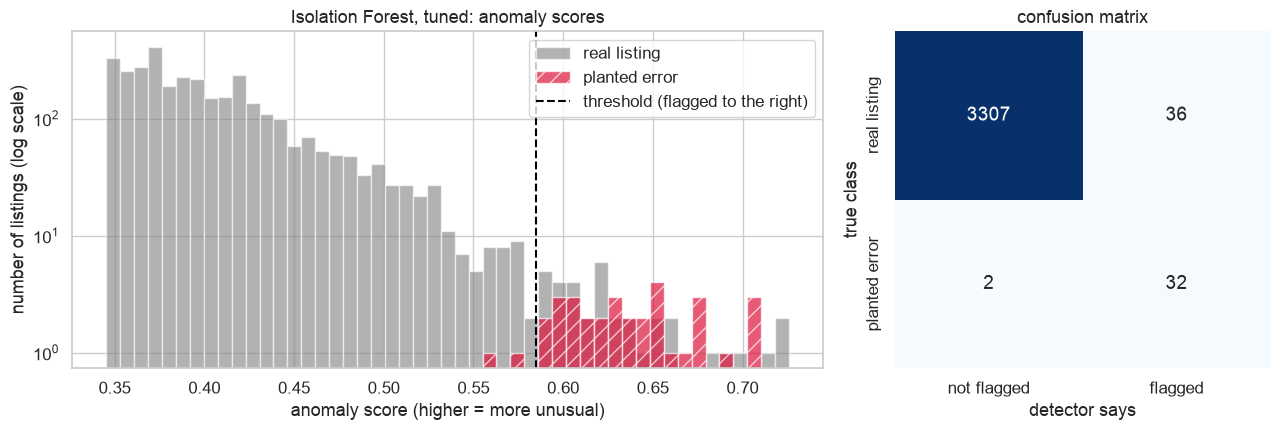

In [12]:
# A fresh copy of the pipeline of 6.1 with the chosen setting
tuned_forest_pipeline = clone(forest_pipeline).set_params(**best_forest_settings)

# fit_predict fits the detector on the evaluation listings and returns -1 for a flagged listing, 1 otherwise
is_flagged = tuned_forest_pipeline.fit_predict(evaluation_features) == -1
# Keep the flags for step 7
flags_by_model["Isolation Forest, tuned"] = is_flagged
# The anomaly score of every listing, higher = more unusual (score_samples gives it with the opposite sign)
anomaly_score = -tuned_forest_pipeline.score_samples(evaluation_features)
# The threshold: tuned_forest_pipeline[-1] is the detector step; offset_ is its cut, with the sign turned like the scores
threshold = -tuned_forest_pipeline[-1].offset_

# Each metric compares the planted errors with the flags
tuned_forest_scores = {
    "model": "Isolation Forest, tuned",
    "flagged": int(is_flagged.sum()),
    "precision": precision_score(is_planted_error, is_flagged),
    "recall": recall_score(is_planted_error, is_flagged),
    "F1": f1_score(is_planted_error, is_flagged),
}
print(f"Isolation Forest, tuned: {tuned_forest_scores['flagged']} flagged, precision {tuned_forest_scores['precision']:.3f}, "
      f"recall {tuned_forest_scores['recall']:.3f}, F1 {tuned_forest_scores['F1']:.3f}")

fig, (ax_scores, ax_counts) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2, 1]})
# Left: one histogram per class on the same bins
# 50 bins of equal width from the lowest to the highest score
bins = np.linspace(anomaly_score.min(), anomaly_score.max(), 50)
ax_scores.hist(anomaly_score[~is_planted_error], bins=bins, color="grey", alpha=0.6, label="real listing")
ax_scores.hist(anomaly_score[is_planted_error], bins=bins, color="crimson", alpha=0.7, hatch="//", label="planted error")
ax_scores.axvline(threshold, color="black", linestyle="--", label="threshold (flagged to the right)")
# The count axis is logarithmic, because there are about 100 real listings for every planted error
ax_scores.set_yscale("log")
ax_scores.set_xlabel("anomaly score (higher = more unusual)")
ax_scores.set_ylabel("number of listings (log scale)")
ax_scores.set_title("Isolation Forest, tuned: anomaly scores")
ax_scores.legend()
# Right: confusion_matrix returns a 2 x 2 array of counts, rows = true class, columns = flagged or not;
# sns.heatmap draws it, annot=True writes the counts in the cells, fmt="d" as whole numbers
counts = confusion_matrix(is_planted_error, is_flagged)
sns.heatmap(counts, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 14},
            xticklabels=["not flagged", "flagged"], yticklabels=["real listing", "planted error"], ax=ax_counts)
ax_counts.set_xlabel("detector says")
ax_counts.set_ylabel("true class")
ax_counts.set_title("confusion matrix")
fig.tight_layout()
plt.show()

**What do you see?** On the evaluation listings, the tuned forest flags 68 listings and finds 32 of the 34 planted errors (recall 0.941). It finds every price × 100 and every price ÷ 100, and 8 of the 10 guests × 10. In the histogram, the planted errors now lie to the right of the threshold (about 0.59). The other 36 flags are false alarms: half of them (19) have a minimum stay of 90 nights or more, and 16 are homes for 10 guests or more. F1 rises from 0.118 to 0.627.

### 6.3 A second detector: the local outlier factor

The **local outlier factor** (LOF) compares the density around a listing with the density around its nearest neighbours: a listing in a much emptier place than its neighbours is unusual. It looks at the neighbourhood of each listing, while Isolation Forest looks at how far a listing lies from the whole cloud. `n_neighbors` sets how many neighbours count; we tune it with `contamination` in the same kind of loop as in 6.2. `StandardScaler` comes first, because LOF measures distances (step 5).

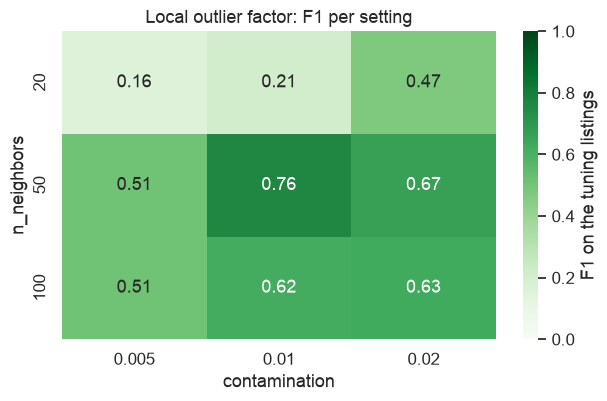

chosen: {'lof__contamination': 0.01, 'lof__n_neighbors': 50}


In [13]:
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

# The processing of step 5, then scaling (LOF compares distances), then the detector
lof_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("scaling", StandardScaler()),
    ("lof", LocalOutlierFactor(n_neighbors=20, contamination=0.01)),
])

# 3 neighbourhood sizes x 3 shares to flag = 9 settings
lof_grid = {"lof__n_neighbors": [20, 50, 100], "lof__contamination": [0.005, 0.01, 0.02]}
# ParameterGrid lists every combination of the values in the grid, as dictionaries
all_settings = list(ParameterGrid(lof_grid))
tuning_f1 = []
for settings in all_settings:
    # A fresh, unfitted copy of the pipeline with this setting
    candidate = clone(lof_pipeline).set_params(**settings)
    # Fit on the tuning listings, flag, and compare the flags with the planted errors
    is_flagged = candidate.fit_predict(tuning_features) == -1
    tuning_f1.append(f1_score(tuning_is_error, is_flagged))

# One row per setting with its F1; pivot makes a table with one cell per combination of the two settings
tuning_results = pd.DataFrame(all_settings)
tuning_results["F1"] = tuning_f1
f1_table = tuning_results.pivot(index="lof__n_neighbors", columns="lof__contamination", values="F1")
# A heatmap of that table, the F1 written in each cell
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(f1_table, annot=True, fmt=".2f", cmap="Greens", vmin=0, vmax=1, annot_kws={"size": 13},
            cbar_kws={"label": "F1 on the tuning listings"}, ax=ax)
ax.set_ylabel("n_neighbors")
ax.set_xlabel("contamination")
ax.set_title("Local outlier factor: F1 per setting")
plt.show()

# The setting with the highest F1 on the tuning listings
best_lof_settings = all_settings[int(np.argmax(tuning_f1))]
print("chosen:", best_lof_settings)

The chosen setting, fitted and scored on the evaluation listings with the same lines as in 6.1. LOF keeps the anomaly score of the listings it was fitted on as `negative_outlier_factor_` (again with the opposite sign). These scores have a long tail, so the score axis is logarithmic.

local outlier factor, tuned: 34 flagged, precision 0.647, recall 0.647, F1 0.647


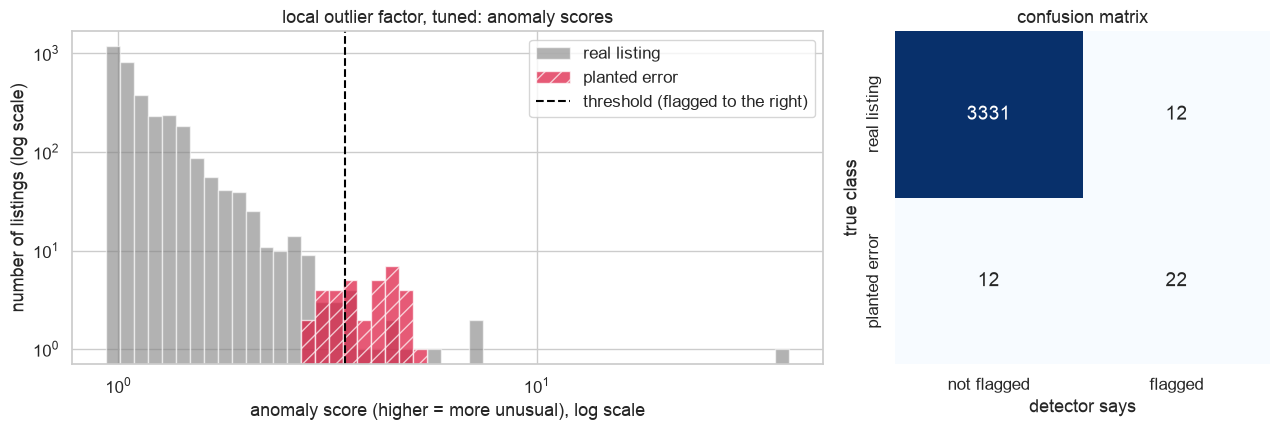

In [14]:
# A fresh copy of the LOF pipeline with the chosen setting
tuned_lof_pipeline = clone(lof_pipeline).set_params(**best_lof_settings)

# fit_predict fits the detector on the evaluation listings and returns -1 for a flagged listing, 1 otherwise
is_flagged = tuned_lof_pipeline.fit_predict(evaluation_features) == -1
# Keep the flags for step 7
flags_by_model["local outlier factor, tuned"] = is_flagged
# The anomaly score of every listing, higher = more unusual: LOF keeps it after fitting, with the opposite sign
anomaly_score = -tuned_lof_pipeline[-1].negative_outlier_factor_
# The threshold: tuned_lof_pipeline[-1] is the detector step; offset_ is its cut, with the sign turned like the scores
threshold = -tuned_lof_pipeline[-1].offset_

# Each metric compares the planted errors with the flags
tuned_lof_scores = {
    "model": "local outlier factor, tuned",
    "flagged": int(is_flagged.sum()),
    "precision": precision_score(is_planted_error, is_flagged),
    "recall": recall_score(is_planted_error, is_flagged),
    "F1": f1_score(is_planted_error, is_flagged),
}
print(f"local outlier factor, tuned: {tuned_lof_scores['flagged']} flagged, precision {tuned_lof_scores['precision']:.3f}, "
      f"recall {tuned_lof_scores['recall']:.3f}, F1 {tuned_lof_scores['F1']:.3f}")

fig, (ax_scores, ax_counts) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [2, 1]})
# Left: one histogram per class on the same bins
# Bin edges spaced evenly on a log axis (np.geomspace), because LOF scores have a long tail
bins = np.geomspace(anomaly_score.min(), anomaly_score.max(), 50)
ax_scores.set_xscale("log")
ax_scores.hist(anomaly_score[~is_planted_error], bins=bins, color="grey", alpha=0.6, label="real listing")
ax_scores.hist(anomaly_score[is_planted_error], bins=bins, color="crimson", alpha=0.7, hatch="//", label="planted error")
ax_scores.axvline(threshold, color="black", linestyle="--", label="threshold (flagged to the right)")
# The count axis is logarithmic, because there are about 100 real listings for every planted error
ax_scores.set_yscale("log")
ax_scores.set_xlabel("anomaly score (higher = more unusual), log scale")
ax_scores.set_ylabel("number of listings (log scale)")
ax_scores.set_title("local outlier factor, tuned: anomaly scores")
ax_scores.legend()
# Right: confusion_matrix returns a 2 x 2 array of counts, rows = true class, columns = flagged or not;
# sns.heatmap draws it, annot=True writes the counts in the cells, fmt="d" as whole numbers
counts = confusion_matrix(is_planted_error, is_flagged)
sns.heatmap(counts, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 14},
            xticklabels=["not flagged", "flagged"], yticklabels=["real listing", "planted error"], ax=ax_counts)
ax_counts.set_xlabel("detector says")
ax_counts.set_ylabel("true class")
ax_counts.set_title("confusion matrix")
fig.tight_layout()
plt.show()

**What do you see?** The loop chooses 50 neighbours and `contamination=0.01` (F1 0.76 on the tuning listings); with 20 neighbours, F1 is lower for every share. On the evaluation listings, LOF flags 34 listings and finds 22 planted errors (precision and recall 0.647). It finds all 11 prices × 100 and 9 of the 13 prices ÷ 100, but only 2 of the 10 guests × 10. A likely reason: these planted listings resemble each other (20 to 40 guests, mostly 1 bedroom, a usual price), so each one has the others as neighbours and does not lie in an empty place. Its 12 false alarms are of another kind than the forest's: mostly cheap private and shared rooms (median price 15.55 euros). The score axis is logarithmic because one real private room scores 40, far above all others.

## 7 Report the results

One table puts the three detectors side by side, in the order we built them, from the scores computed in 6.1 to 6.3. Then a map of the evaluation listings shows what the two tuned detectors flag, and the last two sections ask how sure the numbers are.

In [15]:
# One row per detector, built from the score dictionaries of 6.1, 6.2 and 6.3
test_results = pd.DataFrame([forest_scores, tuned_forest_scores, tuned_lof_scores]).set_index("model").round(3)
test_results

,flagged,precision,recall,F1
model,,,,
Isolation Forest,34,0.118,0.118,0.118
"Isolation Forest, tuned",68,0.471,0.941,0.627
"local outlier factor, tuned",34,0.647,0.647,0.647


The next figure is **interactive**: plotly draws it in the browser, so you can hover over a point to read the listing behind it, zoom with the mouse, and click a group in the legend to hide it. `px.scatter` draws one point per row of a table; `facet_col` draws one panel per detector, and `hover_data` lists the columns shown when you hover. The flags come from `flags_by_model`, filled in section 6. Each listing gets one of four outcomes: a planted error that is found or missed, a real listing that is flagged (a false alarm, which may still be a real error), or a real listing that is not flagged.

In [16]:
import plotly.express as px
import plotly.io as pio

# Save the figure in two forms: one that VS Code and JupyterLab draw, and HTML that loads plotly from the web
pio.renderers.default = "plotly_mimetype+notebook_connected"

# One table with a row per (evaluation listing, tuned detector)
outcome_tables = []
for model_name in ["Isolation Forest, tuned", "local outlier factor, tuned"]:
    is_flagged = flags_by_model[model_name]
    # np.select picks the first outcome whose condition is True
    outcome = np.select(
        [is_planted_error & is_flagged, is_planted_error & ~is_flagged, ~is_planted_error & is_flagged],
        ["planted error, found", "planted error, missed", "real listing, flagged"],
        default="real listing, not flagged",
    )
    outcome_tables.append(evaluation_listings.assign(detector=model_name, outcome=outcome))
flag_map = pd.concat(outcome_tables)
# A small random shift of the guest numbers, so listings with the same number of guests do not hide each other
jitter_rng = np.random.default_rng(0)
flag_map["guests (jittered)"] = flag_map["accommodates"] + jitter_rng.uniform(-0.3, 0.3, len(flag_map))

fig = px.scatter(
    flag_map, x="guests (jittered)", y="price", color="outcome", symbol="outcome", facet_col="detector",
    log_y=True, opacity=0.6, height=520, width=1100,
    category_orders={"outcome": ["real listing, not flagged", "real listing, flagged",
                                 "planted error, found", "planted error, missed"]},
    color_discrete_sequence=["lightgrey", "darkorange", "seagreen", "crimson"],
    hover_data=["id", "room_type", "price", "accommodates", "bedrooms", "minimum_nights", "planted_error"],
    labels={"price": "price per night (€, log scale)"},
    title="Evaluation listings: what each tuned detector flags",
)
fig.update_xaxes(title_text="guests the listing accommodates (persons, jittered)")
# Panel titles: "detector=Isolation Forest, tuned" becomes "Isolation Forest, tuned"
for annotation in fig.layout.annotations:
    annotation.text = annotation.text.split("=")[1]
fig.show()

**What do you see?** Hover over the points to read the listings. In both panels, the found errors (green squares) lie at the edges of the cloud: far above it (prices × 100, from 754 to 35,000 euros) and far below it (prices ÷ 100, below 3 euros). The guests × 10 lie to the right, at 20 to 60 guests; the forest finds most of them, LOF misses most of them (red crosses). The false alarms (orange) differ: the forest flags large homes and long minimum stays, LOF flags cheap rooms in the low band. Both flag the most expensive listing, 10,025 euros a night for 7 guests. The two detectors flag 28 listings in common, 22 planted errors and 6 real listings. These orange listings are not known to be wrong: they are the real listings the team should check first.

### 7.1 How sure is each score?

The evaluation listings are one sample: another split, and other listings in the evaluation half, would give slightly different scores. A **95% confidence interval** shows how far a score could move for that reason: over many such samples, 95 of 100 intervals contain the detector's true score.

**Precision and recall are shares**, so they have a formula interval. The usual formula is the share plus or minus 1.96 standard errors:

$$\text{95\% CI} = p \pm 1.96 \sqrt{\frac{p\,(1-p)}{n}}$$

Read aloud: "p plus or minus 1.96 times the square root of p times one minus p, divided by n." For recall, n is the number of planted errors in the evaluation listings; for precision, the number of flagged listings. The 1.96 assumes a bell-shaped (normal) curve, which needs about 10 of each outcome (10 found and 10 missed errors). With only 34 planted errors, some detectors miss fewer than 10, so we use the **Wilson interval**, which does not need the bell shape: `proportion_confint(count, total, method="wilson")` from statsmodels.

In [17]:
from statsmodels.stats.proportion import proportion_confint

# For each detector: the counts behind precision and recall, then the Wilson interval of each share
n_planted = int(is_planted_error.sum())
share_rows = []
for model_name, is_flagged in flags_by_model.items():
    n_flagged = int(is_flagged.sum())
    n_found = int((is_planted_error & is_flagged).sum())
    precision_lower, precision_upper = proportion_confint(n_found, n_flagged, method="wilson")
    recall_lower, recall_upper = proportion_confint(n_found, n_planted, method="wilson")
    share_rows.append({
        "model": model_name,
        "precision": f"{n_found}/{n_flagged} = {n_found / n_flagged:.3f}",
        "precision 95% CI": f"{precision_lower:.3f} to {precision_upper:.3f}",
        "recall": f"{n_found}/{n_planted} = {n_found / n_planted:.3f}",
        "recall 95% CI": f"{recall_lower:.3f} to {recall_upper:.3f}",
    })
share_intervals = pd.DataFrame(share_rows).set_index("model")
share_intervals

,precision,precision 95% CI,recall,recall 95% CI
model,,,,
Isolation Forest,4/34 = 0.118,0.047 to 0.266,4/34 = 0.118,0.047 to 0.266
"Isolation Forest, tuned",32/68 = 0.471,0.357 to 0.588,32/34 = 0.941,0.809 to 0.984
"local outlier factor, tuned",22/34 = 0.647,0.479 to 0.785,22/34 = 0.647,0.479 to 0.785


**What do you see?** The intervals are wide, because there are only 34 planted errors. For the default forest, recall 4/34 = 0.118 could be anywhere from 0.047 to 0.266. For the tuned forest, 32/34 = 0.941 has the interval 0.809 to 0.984: it is not symmetric, because it cannot pass 1. The normal formula would need about 10 missed errors, and the tuned forest misses 2. The precision of the tuned forest, 0.357 to 0.588, means that about one flag in two is a planted error. The tuned forest and LOF differ in kind: the forest's recall interval lies above that of LOF (0.479 to 0.785), while LOF's precision interval lies higher than the forest's, and the two precision intervals overlap.

**The bootstrap, for F1.** F1 has no simple formula for its interval. The bootstrap needs none. The flags of each detector stay fixed; only the evaluation listings are drawn again:

1. Draw as many evaluation listings as there are, **with replacement**: some listings appear twice, some not at all.
2. Compute F1 on these listings.
3. Repeat 1,000 times. The middle 95% of the 1,000 values, from the 2.5th to the 97.5th percentile, is the interval.

`rng.integers(0, n, size=(1000, n))` draws the row positions of all 1,000 resamples at once, one resample per row of the array. F1 is computed from three counts: found errors (`found`), false alarms (`false_alarms`) and missed errors (`missed`), as 2 · found / (2 · found + false alarms + missed).

In [18]:
# 1,000 resamples of the evaluation listings; each row of resampled_rows holds the positions of one resample
rng = np.random.default_rng(0)
n_resamples = 1000
n_evaluation_rows = len(is_planted_error)
resampled_rows = rng.integers(0, n_evaluation_rows, size=(n_resamples, n_evaluation_rows))
# The true class of every listing in every resample: an array of 1,000 rows
resampled_errors = is_planted_error[resampled_rows]

# The F1 of every detector on every resample, from the three counts of each resample (sum along each row)
bootstrap_f1 = {}
for model_name, is_flagged in flags_by_model.items():
    resampled_flags = is_flagged[resampled_rows]
    found = (resampled_errors & resampled_flags).sum(axis=1)
    false_alarms = (~resampled_errors & resampled_flags).sum(axis=1)
    missed = (resampled_errors & ~resampled_flags).sum(axis=1)
    bootstrap_f1[model_name] = 2 * found / (2 * found + false_alarms + missed)

# The interval: the 2.5th and the 97.5th percentile of the 1,000 F1 values
interval_rows = []
for model_name, f1_values in bootstrap_f1.items():
    lower, upper = np.percentile(f1_values, [2.5, 97.5])
    interval_rows.append({"model": model_name, "F1": test_results.loc[model_name, "F1"],
                          "95% CI from": lower, "95% CI to": upper})
f1_intervals = pd.DataFrame(interval_rows).set_index("model").round(3)
f1_intervals

,F1,95% CI from,95% CI to
model,,,
Isolation Forest,0.118,0.028,0.229
"Isolation Forest, tuned",0.627,0.509,0.732
"local outlier factor, tuned",0.647,0.493,0.760


**What do you see?** The F1 interval of the default forest, 0.028 to 0.229, lies far below those of the two tuned detectors. The intervals of the tuned forest (0.509 to 0.732) and of LOF (0.493 to 0.760) overlap almost completely. Whether two detectors really differ is a separate question, and section 7.2 answers it.

### 7.2 Is the next detector really better? The interval of the difference

The F1 intervals of the two tuned detectors overlap. Many people read this as "the detectors are equally good", but that is a common mistake: overlap of two separate intervals is not the test. A comparison of two classmates shows why.

> Anna and Ben take the same exam every year, and the exam is harder in some years than in others. Anna's scores range from 70 to 90, and Ben's from 75 to 95, so the ranges overlap. But in every year, on the same exam, Ben scores about 5 points more than Anna. Is Ben better? Yes. The overlap only shows that the exams vary in difficulty. To compare them, you compare them on the same exam, which is the difference.

Our detectors are in the same situation: all of them are scored on the **same** evaluation listings. A resample with many planted errors that are easy to find raises every detector; a resample with many hard ones lowers every detector. This shared luck makes each interval wide, and it cancels when we subtract one score from the other.

So we compute the **gain** of each step on every resample, with the same rows for both detectors: the F1 of the later detector minus the F1 of the earlier one. The middle 95% of the 1,000 gains is the **95% interval of the difference**:

- the interval lies above 0: the later detector is better, by about the amount the interval shows; below 0: it is worse;
- the interval contains 0: on these listings we cannot tell the two detectors apart.

In [19]:
# Each step of section 6, as (short label, earlier detector, later detector)
steps = [("forest → tuned forest", "Isolation Forest", "Isolation Forest, tuned"),
         ("tuned forest → tuned LOF", "Isolation Forest, tuned", "local outlier factor, tuned")]

gain_rows = []
for label, earlier, later in steps:
    # The same resampled rows for both detectors, so every gain compares them on the same listings
    gains = bootstrap_f1[later] - bootstrap_f1[earlier]
    lower, upper = np.percentile(gains, [2.5, 97.5])
    gain_rows.append({"step": label,
                      "gain in F1": test_results.loc[later, "F1"] - test_results.loc[earlier, "F1"],
                      "95% CI from": lower, "95% CI to": upper})
f1_gains = pd.DataFrame(gain_rows).set_index("step").round(3)
f1_gains

,gain in F1,95% CI from,95% CI to
step,,,
forest → tuned forest,0.509,0.372,0.639
tuned forest → tuned LOF,0.020,-0.120,0.153


A histogram of the 1,000 gains of each step shows the same thing as a picture. The solid lines mark the 95% interval, the dashed line a gain of 0, "no difference".

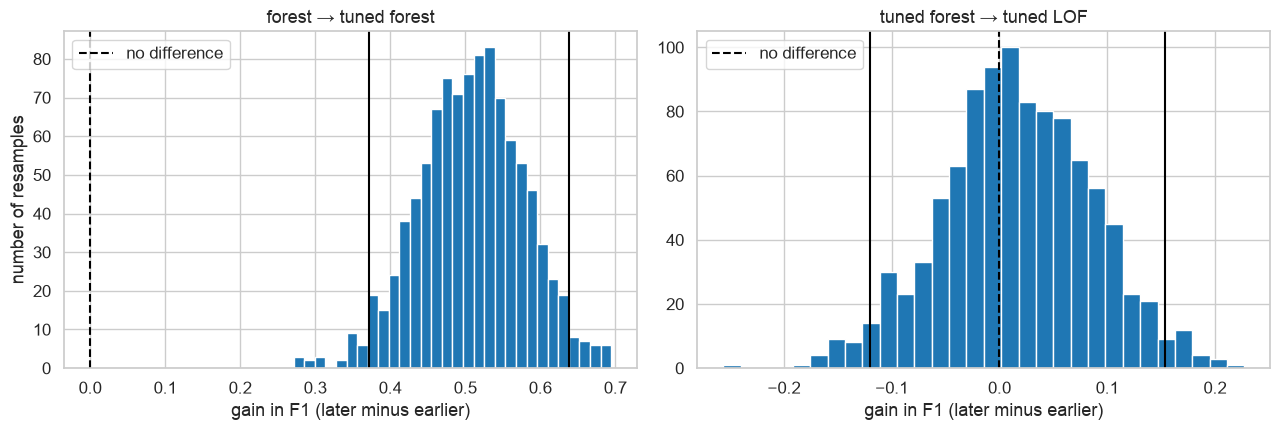

In [20]:
# One panel per step of section 6: the histogram of its 1,000 gains in F1
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (label, earlier, later) in zip(axes, steps):
    gains = bootstrap_f1[later] - bootstrap_f1[earlier]
    ax.hist(gains, bins=30, color="tab:blue")
    # The 95% interval as two solid lines, the value 0 as a dashed line
    for bound in np.percentile(gains, [2.5, 97.5]):
        ax.axvline(bound, color="black")
    ax.axvline(0, color="black", linestyle="--", label="no difference")
    ax.set_title(label)
    ax.set_xlabel("gain in F1 (later minus earlier)")
    ax.legend()
axes[0].set_ylabel("number of resamples")
fig.tight_layout()
plt.show()

**What do you see?** Left: tuning raises F1 by 0.372 to 0.639. The whole interval lies far above the dashed line at 0, so the tuned forest is better than the default one, by about half of the F1 scale. Right: the gain from the tuned forest to LOF lies between −0.120 and 0.153, and the dashed line at 0 is in the middle of the histogram. On these listings we cannot tell the two tuned detectors apart. Note that they also flag different numbers of listings (68 and 34): the forest finds more errors and raises more false alarms, LOF the other way round. The choice between them depends on how many listings the team can check.

**What the bootstrap shows, and what it does not.** The bootstrap treats every evaluation listing as an independent draw. Listings of the same host can be near copies of each other, so they are not fully independent, and the intervals are somewhat too narrow. For the formula interval of a share, the normal approximation needs about 10 of each outcome, which is why 7.1 uses the Wilson interval. The intervals show how much the scores depend on which listings landed in the evaluation half. They do not include three other sources of chance: which rows got a planted error, the random trees of the forest, and the choice of the setting on the tuning listings. Most important, they measure how well the detectors find **our three kinds of planted error**. Real errors may look different, and a flagged real listing may be a real error that we count as a false alarm.

### 7.3 Use the model on a new input

The finding recommends the tuned Isolation Forest. If the team uses it, every new listing is checked when it comes in. A new listing arrives as one row of the four facts the detector uses: price, minimum stay, guests and bedrooms. The fitted `tuned_forest_pipeline` of 6.2 runs both of its steps on it: the processing of step 5 (median fill and log), then the forest. Nothing is refitted.

- `predict` returns 1 for a normal listing and −1 for a flagged one.
- `decision_function` returns how far the listing lies from the threshold: `score_samples` minus `offset_`. **Negative means flagged**, positive means normal, and the further from 0, the clearer the answer. It is the threshold minus the anomaly score of 6.1: a listing whose anomaly score lies above the threshold gets a negative value.

We build two listings: an ordinary flat, and the same flat with the price typed with two zeros too many, like the planted errors of step 4. (LOF would need `novelty=True` to score new rows; the forest needs nothing extra.)

In [21]:
# Two new listings, one per row, with the four columns the detector needs (feature_columns), in the same order.
# The second one is the first with the price typed with two zeros too many: 95 € becomes 9,500 €
new_listings = pd.DataFrame({
    "price": [95.0, 9500.0],
    "minimum_nights": [3, 3],
    "accommodates": [2, 2],
    "bedrooms": [1, 1],
}, index=["ordinary flat", "price × 100"])
print("the new input:")
print(new_listings)

# predict runs the processing of step 5 and the fitted forest; it returns 1 (normal) or -1 (flagged) per listing
new_listing_flag = tuned_forest_pipeline.predict(new_listings)
# decision_function returns score_samples minus offset_: below 0 means flagged
new_listing_decision = tuned_forest_pipeline.decision_function(new_listings)
# The anomaly score of 6.1 and 6.2: score_samples with the sign turned, higher = more unusual;
# the threshold of the tuned forest: offset_ of its detector step, with the sign turned in the same way
tuned_forest_threshold = -tuned_forest_pipeline[-1].offset_
new_listing_anomaly_score = -tuned_forest_pipeline.score_samples(new_listings)

print("\npredict returns:", new_listing_flag)
print("decision_function returns:", new_listing_decision.round(3))
print("anomaly score:", new_listing_anomaly_score.round(3), f"(threshold {tuned_forest_threshold:.3f}, flagged above it)")
for listing_name, flag, decision in zip(new_listings.index, new_listing_flag, new_listing_decision):
    answer = "flagged: send it to the team" if flag == -1 else "normal: no check needed"
    print(f"{listing_name}: {answer} (decision_function {decision:+.3f})")

the new input:
                price  minimum_nights  accommodates  bedrooms
ordinary flat    95.0               3             2         1
price × 100    9500.0               3             2         1

predict returns: [ 1 -1]
decision_function returns: [ 0.221 -0.008]
anomaly score: [0.364 0.593] (threshold 0.585, flagged above it)
ordinary flat: normal: no check needed (decision_function +0.221)
price × 100: flagged: send it to the team (decision_function -0.008)


**What do you see?** The input is two rows of four facts; the output of `predict` is one flag per listing: `[ 1 -1]`. The ordinary flat (95 €, 3 nights, 2 guests, 1 bedroom) is normal, with `decision_function` +0.221, far on the normal side. The same flat at 9,500 € is flagged, with `decision_function` −0.008: its anomaly score, 0.593, lies just above the threshold, 0.585. The sign gives the answer, but the margin is small. As the histogram in 6.2 showed, the forest's anomaly scores lie in a narrow band, and the planted errors sit only a little above the threshold. So a deployed forest would send this listing to the team, but a typing error that is a little less extreme could slip through.

**Finding.** Isolation Forest, tuned to use all listings per tree and to flag 2% of them, finds 32 of the 34 planted errors in the evaluation listings (recall 0.941, 95% Wilson interval 0.809 to 0.984) with F1 0.627 (95% CI 0.509 to 0.732), and about half of its 68 flags are planted errors (precision 0.471, 0.357 to 0.588). Tuning raised F1 by 0.509 over the default settings (95% CI of the difference 0.372 to 0.639), while the tuned local outlier factor flags half as many listings and reaches about the same F1 (difference 0.020, 95% CI −0.120 to 0.153), so these listings cannot tell the two tuned detectors apart. One limitation: the scores count only three kinds of planted typing error, so they do not say how many of the flagged real listings are wrong; the team should check the flags and record what they find, which gives real labels for a better evaluation.

## 8 A recent method

Isolation Forest and LOF need settings, as 6.2 and 6.3 showed. **ECOD** (Li, Zhao, Hu, Botta, Ionescu and Chen, *IEEE TKDE*, 2022) needs none. For each column it estimates how rare a value is in each tail of that column's distribution, and adds these tail probabilities over the columns. The column with the largest term says why a listing is unusual, which helps the team that checks it. It is part of PyOD, a Python library of outlier detectors (Chen and colleagues, PyOD 2, 2025).

PyOD is not installed in the course environment. With it, the detector step would read:

```python
from pyod.models.ecod import ECOD

# contamination plays the same role as in Isolation Forest: the share of listings to flag
ecod_detector = ECOD(contamination=0.02)
ecod_detector.fit(preprocessing.fit_transform(evaluation_features))
ecod_flags = ecod_detector.labels_ == 1      # PyOD marks a flagged listing with 1
```

Compare it with the table above in the same way: the same planted errors, the same evaluation listings and the same scores.

> 📖 **Read more:** [ECOD paper](https://arxiv.org/abs/2201.00382) (Li et al., *IEEE TKDE*, 2022): how the tail probabilities are computed, and a benchmark on 30 data sets.